# Шаг 1. Текст — это числа

Нейросеть умеет складывать и умножать только **числа**. Картинка уже была числами (пиксели),
а с текстом нужно договориться: разрезать его на кусочки — **токены** — и дать каждому кусочку номер.
Набор всех токенов с номерами называется **словарь**.

Учиться будем на романе «Евгений Онегин» (главы 1–8, файл `onegin.txt`).

**Как резать текст — три способа:**

| Способ | Пример для «онегин» | Словарь | Плюсы и минусы |
|--------|---------------------|---------|----------------|
| по символам | о · н · е · г · и · н | ~75 | маленький словарь, любое слово записать можно; но текст получается длинным |
| по словам | онегин | ~8 000 | коротко; но словарь огромный, а незнакомое слово модель не запишет вообще |
| BPE (склейка частых пар) | онегин или пре · ди · сло · ви · й | сколько захотим | золотая середина — так делают ChatGPT, Claude и другие большие модели |

**Структура примера (алгоритм):**
1. Читаем текст, считаем символы.
2. Строим словарь символов, переводим строку в номера и обратно.
3. Убеждаемся, что номер — это просто ярлык, и что символа не из словаря модель не знает.
4. Рисуем, какие буквы встречаются чаще.
5. Режем текст на слова: сколько разных слов, сколько встречаются один раз.
6. Разбираем BPE на игрушечном примере из трёх слов, затем делаем 200 склеек на всём романе.
7. Сравниваем, сколько токенов занимает одна строка при трёх способах.

In [ ]:
# Настройка для Google Colab. На своём компьютере эта ячейка ничего не делает.
# В Colab нужна папка machine_vision на Google Диске (в ней session01–session05 и dataset).
import os
import sys

try:
    from google.colab import drive
except ImportError:
    drive = None

if drive:
    drive.mount("/content/drive")
    COLAB_ROOT = "/content/drive/MyDrive/machine_vision"
    os.chdir(f"{COLAB_ROOT}/session05")  # здесь лежит common.py и сохраняются результаты
    sys.path.insert(0, os.getcwd())

## Общий модуль `common.py`

Во всех примерах сессии используется модуль `common.py` из этой же папки:

| Имя | Что делает |
|-----|------------|
| `load_names()`, `load_text()` | русские имена из `names.txt` и «Евгений Онегин» (главы 1–8) из `onegin.txt` |
| `CharTokenizer(text)` | словарь символов: `encode` — строка → номера, `decode` — номера → строка, `vocab_size` — размер словаря |
| `name_tokenizer`, `bigram_pairs`, `bigram_counts` | словарь для имён (точка `.` — начало/конец имени), пары «буква → следующая», таблица подсчётов |
| `sample_name(probs, tok)` | придумать имя по таблице вероятностей |
| `apply_temperature(logits, T)` | вероятности из «сырых оценок» с температурой T |
| `MiniGPT`, `Block`, `SelfAttention` | маленький трансформер по символам |
| `save_gpt`, `load_gpt` | сохранить / загрузить GPT вместе со словарём |
| `load_session04()` | модуль `common.py` из сессии 4 (кошки и собаки, `SimpleCNN`) — для бонуса |
| `show()` | показать графики matplotlib |

> Запускайте примеры из папки `session05`, иначе `import common` не найдёт модуль.
> Библиотеки: `pip install -r requirements.txt`. Тексты лежат в этой же папке, интернет не нужен.

## 1. Смотрим на текст

`load_text()` возвращает весь роман одной строкой. `\n` — символ перевода строки: для модели это такой же символ, как буква.
Значит, модель сможет научиться и тому, **где** кончается стихотворная строка.

In [1]:
import re
from collections import Counter

import matplotlib.pyplot as plt

from common import CharTokenizer, load_text, show

text = load_text()
print("Символов в тексте:", len(text))
print("Строк:", text.count("\n"))
print(text[:200])

Символов в тексте: 138204
Строк: 5619
ГЛАВА ПЕРВАЯ

«Мой дядя самых честных правил,
Когда не в шутку занемог,
Он уважать себя заставил
И лучше выдумать не мог;
Его пример другим наука;
Но, Боже мой, какая скука
С больным сидеть и день и н


## 2. Словарь символов

`CharTokenizer` собирает все разные символы текста, сортирует их и нумерует: `stoi` — «символ → номер», `itos` — «номер → символ».
Заглавные и строчные буквы — разные символы, пробел и перевод строки — тоже символы.

`encode` и `decode` — взаимно обратные: из номеров всегда получается ровно исходная строка, ничего не теряется.

In [2]:
# --- 1. Токены-символы
tok = CharTokenizer(text)
print("Разных символов (размер словаря):", tok.vocab_size)
print("Словарь:", repr("".join(tok.chars)))

line = "Мой дядя самых честных правил"
ids = tok.encode(line)
print("Строка:", line)
print("Номера:", ids)
print("Обратно:", tok.decode(ids))

Разных символов (размер словаря): 75
Словарь: '\n !(),-.:;?«»АБВГДЕЖЗИКЛМНОПРСТУФХЦЧШЬЭЮЯабвгдежзийклмнопрстуфхцчшщъыьэюяё—'
Строка: Мой дядя самых честных правил
Номера: [24, 55, 50, 1, 45, 72, 45, 72, 1, 58, 41, 53, 68, 62, 1, 64, 46, 58, 59, 54, 68, 62, 1, 56, 57, 41, 43, 49, 52]
Обратно: Мой дядя самых честных правил


### Номер — это просто ярлык

У пикселя число имеет смысл: 200 ярче, чем 100. А у токена номер — как номер в классном журнале:
«а» = 41 и «б» = 42 стоят рядом только потому, что мы отсортировали буквы по алфавиту.
«а» и «А» для нас одна буква, а номера у них далеко. Поэтому сеть не может работать прямо с номерами —
в шаге 3 каждый номер превратится в набор чисел (**эмбеддинг**), который сеть подберёт сама.

Второй урок: символа, которого не было в тексте (например, смайлика), нет в словаре. Модель не сможет ни прочитать его, ни написать.
`KeyError` — это Python говорит «такого ключа в словаре нет».

In [3]:
# Номер — просто ярлык: у соседних номеров буквы не «похожи», а символа не из словаря нет вовсе
for a, b in [("а", "б"), ("а", "я"), ("а", "А")]:
    print(f"«{a}» = {tok.stoi[a]}, «{b}» = {tok.stoi[b]}: разница номеров {abs(tok.stoi[a] - tok.stoi[b])}")
try:
    tok.encode("Привет, 🙂")
except KeyError as err:
    print("Символа", err, "нет в словаре — модель не сможет его ни прочитать, ни написать")

«а» = 41, «б» = 42: разница номеров 1
«а» = 41, «я» = 72: разница номеров 31
«а» = 41, «А» = 13: разница номеров 28
Символа '🙂' нет в словаре — модель не сможет его ни прочитать, ни написать


### Частоты букв

Буквы встречаются очень неравномерно: «о», «е», «а» — частые, «ъ», «ф», «э» — редкие.
Это первое, что «выучит» любая языковая модель: если ничего не знаешь о тексте, ставь на «о» — не ошибёшься чаще всего.

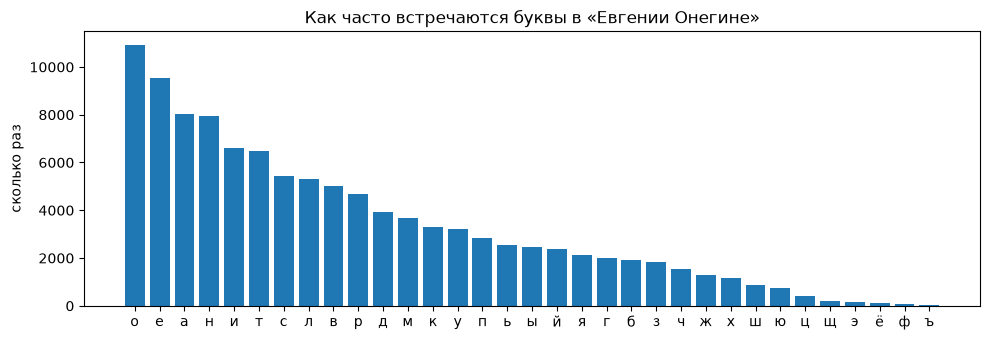

In [4]:
letters = Counter(ch for ch in text.lower() if ch.isalpha())
top = letters.most_common(33)
plt.figure(figsize=(10, 3.5))
plt.bar([ch for ch, _ in top], [n for _, n in top])
plt.title("Как часто встречаются буквы в «Евгении Онегине»")
plt.ylabel("сколько раз")
plt.tight_layout()
plt.savefig("char_freq.png", dpi=100)
show()

## 3. Словарь слов

Если резать по словам, словарь сразу вырастает до тысяч слов, причём большинство встречается **всего один раз** —
по одному примеру модель ничего о слове не узнает. А слова, которого не было в тексте («нейросеть»), в словаре нет совсем.

`re.findall(r"[а-яё]+", ...)` — найти все куски подряд идущих русских букв; знаки препинания и пробелы при этом пропадают.

In [5]:
# --- 2. Токены-слова
words = re.findall(r"[а-яё]+", text.lower())
vocab = Counter(words)
print("Слов в тексте:", len(words))
print("Разных слов (размер словаря):", len(vocab))
print("Слов, которые встретились всего один раз:", sum(1 for n in vocab.values() if n == 1))
print("Самые частые слова:", vocab.most_common(10))
for word in ["онегин", "татьяна", "нейросеть"]:
    print(f"Слово «{word}» в словаре: {'да' if word in vocab else 'НЕТ — модель его не знает'}")

# --- 3. Золотая середина: склеиваем частые пары (BPE, как в настоящих GPT)
corpus = {tuple(word): n for word, n in vocab.items()}   # слово → кусочки (сначала по буквам) и частота

Слов в тексте: 22353
Разных слов (размер словаря): 8265
Слов, которые встретились всего один раз: 5807
Самые частые слова: [('и', 997), ('в', 602), ('не', 383), ('он', 290), ('на', 260), ('с', 239), ('я', 237), ('но', 189), ('как', 188), ('что', 166)]
Слово «онегин» в словаре: да
Слово «татьяна» в словаре: да
Слово «нейросеть» в словаре: НЕТ — модель его не знает


## 4. BPE: склеиваем частые пары

Алгоритм **BPE** (*byte pair encoding*):
1. Сначала каждое слово — это просто буквы.
2. Находим самую частую соседнюю пару кусочков во всём тексте (например, «н» + «е»).
3. Склеиваем её в новый кусочек «не» везде, где она встречается, и добавляем в словарь.
4. Повторяем столько раз, каким хотим сделать словарь.

### Сначала — на игрушечном примере

Пусть в «тексте» всего три слова: «мама» (4 раза), «мак» (3 раза) и «ком» (2 раза). Посчитаем пары вручную:
- «ма» — дважды в каждой «маме» (4 · 2 = 8) и один раз в каждом «маке» (3) — всего **11**;
- «ам» — 4, «ак» — 3, «ко» и «ом» — по 2.

Побеждает «ма». После склейки «мама» = «ма · ма», и теперь самая частая пара — уже из двух **кусочков**: «ма» + «ма».
Так из букв вырастают слоги, а из слогов — целые слова. Проверьте в выводе ниже, что всё совпало с подсчётом на бумаге.
Функция `count_pairs` подсчитывает пары, `merge` — делает одну склейку в одном слове.

In [6]:
def merge(pieces, a, b):
    """Склеить в одном слове все соседние пары (a, b) в один кусочек a + b."""
    out, i = [], 0
    while i < len(pieces):
        if i + 1 < len(pieces) and pieces[i] == a and pieces[i + 1] == b:
            out.append(a + b)
            i += 2
        else:
            out.append(pieces[i])
            i += 1
    return tuple(out)


def count_pairs(corpus):
    """Сколько раз каждая соседняя пара кусочков встречается во всех словах (с учётом частоты слов)."""
    pairs = Counter()
    for pieces, n in corpus.items():
        for a, b in zip(pieces, pieces[1:]):
            pairs[a, b] += n
    return pairs


# Сначала — игрушечный пример, который легко проверить в уме: три слова и их частоты
toy = {tuple("мама"): 4, tuple("мак"): 3, tuple("ком"): 2}
for step in range(1, 4):
    pairs = count_pairs(toy)
    print(f"Шаг {step}. Пары:", ", ".join(f"«{a}{b}» {n}" for (a, b), n in pairs.most_common()))
    (a, b), n = pairs.most_common(1)[0]
    toy = {merge(pieces, a, b): count for pieces, count in toy.items()}
    print(f"  склеиваем «{a}» + «{b}» → слова теперь:", ", ".join(" · ".join(p) for p in toy))

Шаг 1. Пары: «ма» 11, «ам» 4, «ак» 3, «ко» 2, «ом» 2
  склеиваем «м» + «а» → слова теперь: ма · ма, ма · к, к · о · м
Шаг 2. Пары: «мама» 4, «мак» 3, «ко» 2, «ом» 2
  склеиваем «ма» + «ма» → слова теперь: мама, ма · к, к · о · м
Шаг 3. Пары: «мак» 3, «ко» 2, «ом» 2
  склеиваем «ма» + «к» → слова теперь: мама, мак, к · о · м


### Теперь на всём романе

Первые склейки — «не», «по», «ст», «на» — частые слоги и приставки русского языка: алгоритм «открыл» их сам, просто считая пары.

Чтобы разрезать **новое** слово, повторяем все склейки в том же порядке, в каком они были найдены (функция `bpe`).
Частые слова («онегин», «татьяна») в итоге становятся одним токеном, а редкие и незнакомые
разрезаются на знакомые кусочки — поэтому записать можно **любое** слово.

In [7]:
merges = []
for step in range(1, 201):
    (a, b), n = count_pairs(corpus).most_common(1)[0]
    merges.append((a, b))
    corpus = {merge(pieces, a, b): count for pieces, count in corpus.items()}
    if step <= 20 or step % 50 == 0:
        print(f"Склейка {step:3d}: «{a}» + «{b}» → «{a + b}» (встречалась {n} раз)")


def bpe(word):
    """Разрезать любое слово на кусочки, повторив все склейки по порядку."""
    pieces = tuple(word)
    for a, b in merges:
        pieces = merge(pieces, a, b)
    return pieces


print("Размер словаря BPE: буквы + склейки =", len(set("".join(words))) + len(merges))
for word in ["онегин", "татьяна", "предисловий", "нейросеть"]:
    print(f"{word:>12} → {' | '.join(bpe(word))}")

Склейка   1: «н» + «е» → «не» (встречалась 1505 раз)
Склейка   2: «н» + «о» → «но» (встречалась 1375 раз)
Склейка   3: «с» + «т» → «ст» (встречалась 1318 раз)
Склейка   4: «н» + «а» → «на» (встречалась 1295 раз)
Склейка   5: «п» + «о» → «по» (встречалась 1044 раз)
Склейка   6: «р» + «а» → «ра» (встречалась 956 раз)
Склейка   7: «в» + «о» → «во» (встречалась 893 раз)
Склейка   8: «т» + «о» → «то» (встречалась 865 раз)
Склейка   9: «р» + «о» → «ро» (встречалась 864 раз)
Склейка  10: «е» + «н» → «ен» (встречалась 862 раз)
Склейка  11: «л» + «а» → «ла» (встречалась 833 раз)
Склейка  12: «е» + «т» → «ет» (встречалась 816 раз)
Склейка  13: «н» + «ы» → «ны» (встречалась 810 раз)
Склейка  14: «к» + «о» → «ко» (встречалась 789 раз)
Склейка  15: «г» + «о» → «го» (встречалась 726 раз)
Склейка  16: «р» + «е» → «ре» (встречалась 720 раз)
Склейка  17: «к» + «а» → «ка» (встречалась 687 раз)
Склейка  18: «н» + «и» → «ни» (встречалась 680 раз)
Склейка  19: «л» + «и» → «ли» (встречалась 635 раз)
Склейка

## 5. Одна строка — три токенизации

Модель видит за раз ограниченное число токенов (в шаге 6 — 64). Чем короче текст в токенах, тем больше смысла помещается в это «окно».
По символам строка длинная, по словам — короткая, BPE — посередине.
Сейчас частые слова («мой») уже целые, а более редкие ещё режутся на слоги; с большим числом склеек кусочки станут крупнее.

In [8]:
# Одна и та же строка в трёх токенизациях: чем меньше токенов, тем больше текста влезет в модель
line_words = re.findall(r"[а-яё]+", line.lower())
print(f"«{line}»:")
print("  по символам:", len(tok.encode(line)), "токенов")
print("  по словам:  ", len(line_words), "токенов")
print("  BPE:        ", sum(len(bpe(w)) for w in line_words), "токенов (без пробелов):",
      " · ".join("|".join(bpe(w)) for w in line_words))

«Мой дядя самых честных правил»:
  по символам: 29 токенов
  по словам:   5 токенов
  BPE:         14 токенов (без пробелов): мой · д|я|д|я · са|мы|х · че|ст|ных · пра|ви|л


## Попробуйте сами

1. Сделайте 1000 склеек вместо 200. Как теперь режется «нейросеть»? А «предисловий»? А строка из пункта 5?
2. Посчитайте, сколько токенов занимает первая строфа романа: по символам, по словам и в BPE.
3. Замените `text.lower()` на `text` в подсчёте букв — что изменилось на графике?
4. В игрушечном примере BPE поменяйте частоты, например «ком» сделайте 10 раз. Какая пара склеится первой? Проверьте сначала на бумаге.
5. Почему для маленькой модели (шаг 6) мы выберем токены-символы, а не слова?